In [5]:
from pathlib import Path
import joblib
import pandas as pd

Outputs = Path(r"C:\Users\Soumya_SRB\Desktop\L&T Project Intelligencee\Outputs")

data = joblib.load(Outputs /"prepared_data.joblib")
models = joblib.load(Outputs /"trained_models.joblib")

X_test = data["X_test"]
y_test = data["y_test"]

logistic_model = models["logistic_model"]
forest_model = models["forest_model"]
print("Models and test data loaded successfully.")

Models and test data loaded successfully.


In [6]:
## 5.Model Evaluation and Comparison.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)

models = {"Logistic Regression": logistic_model,
          "Random Forest": forest_model}

results = []
for name, model in models.items():
    predictions = model.predict(X_test)

    results.append(
        {"Model": name,
         "Accuracy": accuracy_score(y_test, predictions),
         "Precision": precision_score(y_test, predictions, pos_label="Yes", zero_division=0),
         "Recall": recall_score(y_test, predictions, pos_label="Yes", zero_division=0),
         "F1 Score": f1_score(y_test, predictions, pos_label="Yes", zero_division=0)})
results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.720,0.658,0.642,0.650
1,Random Forest,0.725,0.655,0.679,0.667


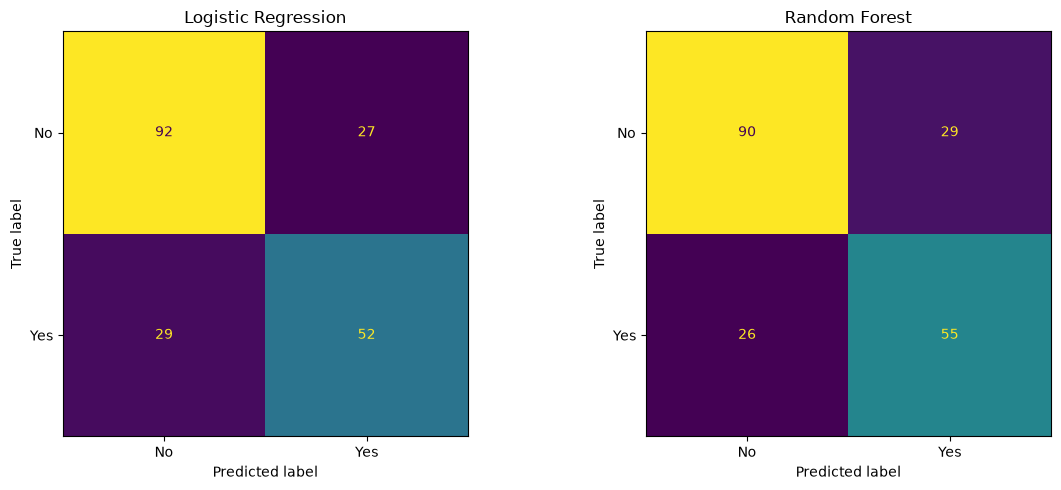

In [7]:
## Plot the confusion matrices.
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=["No", "Yes"],
        ax=ax,
        colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

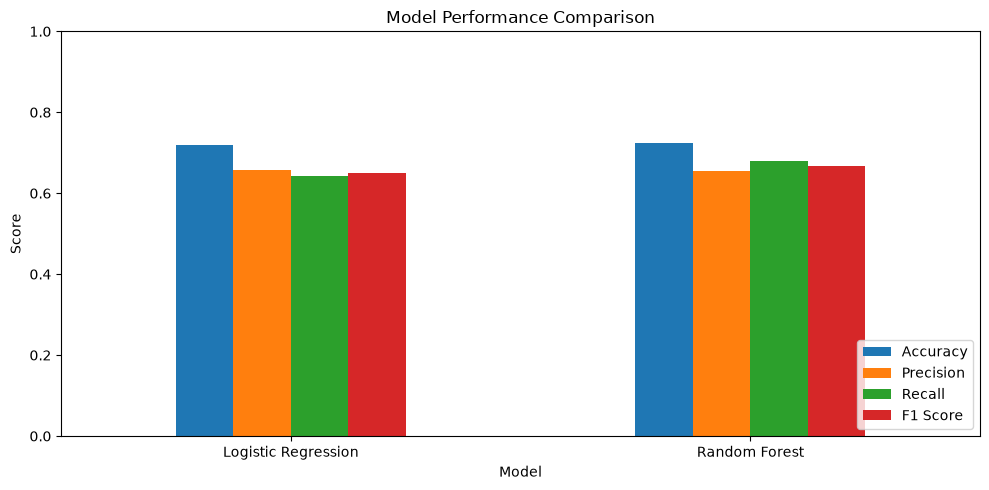

In [8]:
## Compare the results visually.
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()